# The virtual electrode array

Every dataset puts its electrodes somewhere else: 8 around the elbow plus 4 spots (NinaPro DB2, DB7), two rings of 8
(DB8 3 and 5.5 cm below the elbow, GREAT), 8 dry electrodes 20 cm from the wrist (EMG-FK).
`femg.virtual_array.VirtualArray` resamples the **raw EMG** of any of them onto one virtual band: **8 electrodes around
the forearm at the datasets' mean ring height** (z 0.13, 3.4 cm below the elbow; every 45° from palmar), sample by
sample, at the same rate. Your own band is one more layout: it goes through the same matrix at test time. It is
built from ring electrodes only (`layouts: [ring]`): the nearest ring dominates, and NinaPro's spots, whose positions
are only approximate, would replace ring channels. Feature extraction comes later, on these 8 channels only.

```
EMG (T, C), any C, each channel / its active level, positions (C, angle/z/bipolar)
   │  virtual = emg @ M.T       M: one (8, C) matrix per layout
   ▼
virtual EMG (T, 1, 8)
```

The matrix `M = array.matrix(positions, gains)` holds three linear steps:
1. **common average** (monopolar layouts only): subtract the signal every electrode shares;
2. **interpolation**: each virtual electrode is the weighted mean of the real electrodes near it (a Gaussian of the
   skin distance: 1.5 cm around the forearm, 1.5 cm along it);
3. **gains**: each virtual channel is scaled to its own active level, like the real channels.

In C++ this is one matrix-vector product per sample. The settings are in `src/femg/config/virtual_array.yaml`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts" / "tests"))

from test_virtual_array import draw_unrolled, leave_one_out, load, pose_r2, pretty, sources, spectrum

from femg.virtual_array import VirtualArray

ARRAY = VirtualArray.load()
DATASETS = ["emg_fk", "ninapro_db2", "ninapro_db7", "ninapro_db8", "great"]
SECONDS = 300  # per session, one session per dataset
DATA, INTERIM = ROOT / "data" / "processed", ROOT / "data" / "interim"  # virtual EMG, labels / the real EMG

sessions = {}
for name in DATASETS:
    folder = sorted((DATA / name).glob("*/*/meta.json"))[0].parent
    sessions[name] = load(folder, SECONDS, ARRAY, INTERIM)
ARRAY

VirtualArray(n_angles=8, heights=(0.13,), width_around_cm=1.5, width_along_cm=1.5, reach_cm=5.0, layouts=('ring',), common_average=True)

## 1. The matrix of one layout

Left: NinaPro DB2's 12 electrodes (dots, numbered by channel) on the skin unrolled, and the 8 virtual electrodes
(squares), 2.1 cm towards the wrist from its ring. Right: the matrix `M`, one row per virtual electrode, one column per real channel.
Each virtual electrode is mostly the ring channel at its angle, with a little of its two neighbours. The FDS and EDC
spots (9, 10) and the upper-arm channels (11, 12) feed nothing.

matrix: (8, 12)  (virtual electrodes, real channels)
weight by source: {'ring z 0.05': np.float64(1.0)}


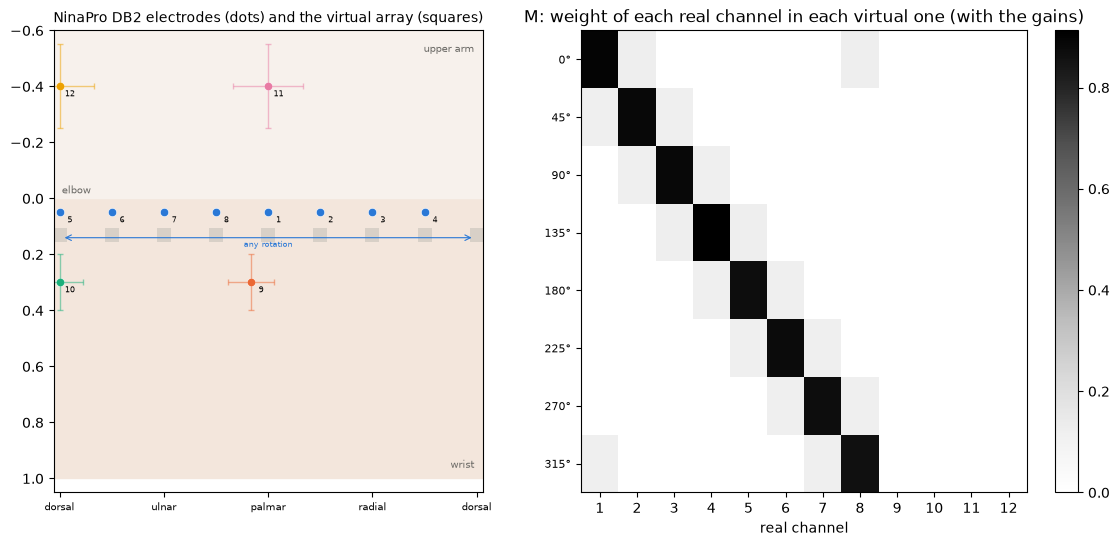

In [2]:
s = sessions["ninapro_db2"]
M = ARRAY.matrix(s["inputs"], s["gains"])
print("matrix:", M.shape, " (virtual electrodes, real channels)")
print("weight by source:", {k: round(v, 2) for k, v in sources(ARRAY, s).items()})

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 6), width_ratios=[1, 1.3])
draw_unrolled(left, s["layout"], ARRAY)
left.set_title("NinaPro DB2 electrodes (dots) and the virtual array (squares)", fontsize=10)
rows = [f"{a:g}°" for z in ARRAY.heights for a in ARRAY.angles]
image = right.imshow(M, cmap="Greys", aspect="auto")
right.set_yticks(range(len(rows)), rows, fontsize=8)
right.set_xticks(range(M.shape[1]), range(1, M.shape[1] + 1))
right.set(xlabel="real channel", title="M: weight of each real channel in each virtual one (with the gains)")
fig.colorbar(image, ax=right)
plt.show()

## 2. One virtual channel and the real ones it comes from

The DB2 virtual electrode at palmar (0°) lies 2.1 cm towards the wrist from ring channel 1. Its signal is mostly that
channel (0.79) with a little of its neighbours 2 and 8 (0.11 each), scaled by its gain. Bipolar electrodes 3 cm apart
share little of their **waveform** (r ≈ 0.3), so even that little mixes the waveform. Their **envelopes** share much more: that is what the virtual channel carries reliably
(section 4).

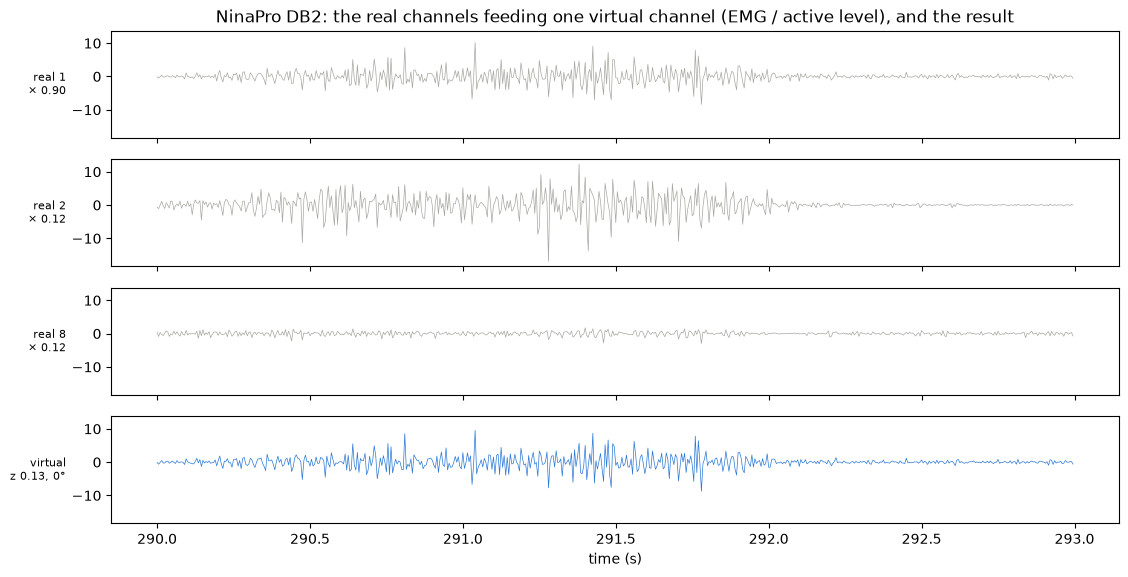

In [3]:
fs = s["meta"]["fs"]
height, column = 0, 0  # palmar
row = M[height * ARRAY.n_angles + column]
feeding = np.flatnonzero(np.abs(row) > 0.05 * np.abs(row).max())
virtual = s["virtual"][:, height, column]

power = np.convolve(virtual**2, np.ones(fs), "same")
start = max(0, int(np.argmax(power) / fs) - 1)
t = np.arange(start * fs, (start + 3) * fs)

fig, axes = plt.subplots(len(feeding) + 1, 1, figsize=(13, 1.6 * (len(feeding) + 1)), sharex=True, sharey=True)
for ax, c in zip(axes, feeding, strict=False):
    ax.plot(t / fs, s["emg"][t, c], color="#a8a7a2", lw=0.5)
    ax.set_ylabel(f"real {c + 1}\n× {row[c]:.2f}", rotation=0, ha="right", va="center", fontsize=8)
axes[-1].plot(t / fs, virtual[t], color="#2a78d6", lw=0.5)
label = f"virtual\nz {ARRAY.heights[height]:g}, {ARRAY.angles[column]:g}°"
axes[-1].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=8)
axes[-1].set_xlabel("time (s)")
axes[0].set_title("NinaPro DB2: the real channels feeding one virtual channel (EMG / active level), and the result")
plt.show()

## 3. What the next stage sees: 8 channels, whatever the layout

The same view for two different recordings: EMG-FK's 8 monopolar electrodes and NinaPro DB8's 16 bipolar electrodes
on two rings (73% of the weight from the row 0.4 cm from the virtual ring, 27% from the one 2.1 cm away). Both become 8
channels at 500 Hz, on the same scale (1 = the channel's active level).

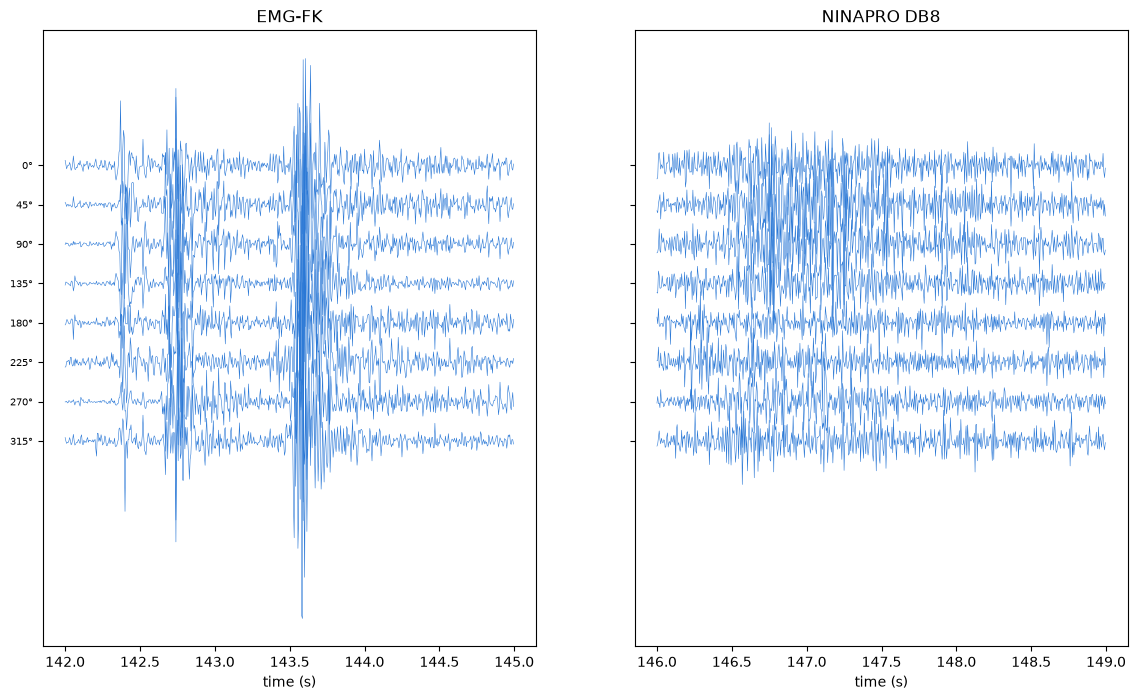

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
for ax, name in zip(axes, ["emg_fk", "ninapro_db8"], strict=True):
    v = sessions[name]["virtual"].reshape(len(sessions[name]["virtual"]), -1)
    fs = sessions[name]["meta"]["fs"]
    power = np.convolve((v**2).sum(axis=1), np.ones(fs), "same")
    start = max(0, int(np.argmax(power) / fs) - 1)
    t = np.arange(start * fs, (start + 3) * fs)
    for k in range(v.shape[1]):
        ax.plot(t / fs, v[t, k] / 4 - k, lw=0.4, color="#2a78d6")
    ax.set(title=pretty(name), xlabel="time (s)")
labels = [f"{a:g}°" for z in ARRAY.heights for a in ARRAY.angles]
axes[0].set_yticks(-np.arange(len(labels)), labels, fontsize=7)
plt.show()

## 4. How good are the virtual signals?

There is no ground truth for a virtual electrode: nobody recorded at those places. The closest test: remove one real
electrode, rebuild it from its neighbours with the same kernel, and compare. For two-ring layouts, also rebuild each
ring from the other ring alone (2.5 cm away): about the case of NinaPro and EMG-FK, whose single rings are 2.1 and
2.6 cm from the virtual one.

The table also shows how much each layout's virtual channels needed scaling (their active level before the gains,
relative to a real channel's) and whether the hand information survives: pose R² from the envelopes of all real
channels, of the real ring of 8 nearest the virtual ring (the fair comparison: as many channels, about the same place),
and of the virtual ring.

In [5]:
rows = {}
for name, s in sessions.items():
    raw, envelope = leave_one_out(ARRAY, [s])
    _, other_ring = leave_one_out(ARRAY, [s], other_height=True)
    real_r2, ring_r2, virtual_r2 = pose_r2([s], ARRAY.heights)
    rows[pretty(name)] = {
        "layout": f"{s['meta']['n_channels']} {s['layout'].kind}",
        "virtual electrodes covered": int(s["covered"].sum()),
        "rebuilt: raw r": raw,
        "rebuilt: envelope r": envelope,
        "from the other ring: envelope r": other_ring,
        "virtual level before gains": np.median(1 / s["gains"][s["covered"]]),
        "pose R² all real": real_r2,
        "pose R² real ring": ring_r2,
        "pose R² virtual": virtual_r2,
    }
pd.DataFrame.from_dict(rows, orient="index").round(2)

,layout,virtual electrodes covered,rebuilt: raw r,rebuilt: envelope r,from the other ring: envelope r,virtual level before gains,pose R² all real,pose R² real ring,pose R² virtual
EMG-FK,8 monopolar,8,0.61,0.82,NaN,0.29,0.26,0.26,0.30
NINAPRO DB2,12 bipolar,8,0.45,0.83,NaN,0.89,0.34,0.32,0.30
NINAPRO DB7,12 bipolar,8,0.61,0.86,NaN,0.88,0.42,0.41,0.40
NINAPRO DB8,16 bipolar,8,0.16,0.77,0.76,0.65,0.23,0.12,0.10
GREAT,16 bipolar,8,0.26,0.61,0.67,0.66,0.63,0.56,0.58


The envelope is rebuilt well everywhere; the raw waveform only where neighbours share a signal (the monopolar band).
One ring predicts the other's envelope at r 0.6-0.8: a single ring 2 cm away is a fair but imperfect stand-in for
what a band at the virtual ring would record. Without the gains, a virtual channel would sit below a real channel's level, by a
different amount for each layout: the gains bring them all to the same scale.

Last check: the spectrum of the virtual channels, as a share of their power. If the datasets were recorded alike, the
curves would overlap.

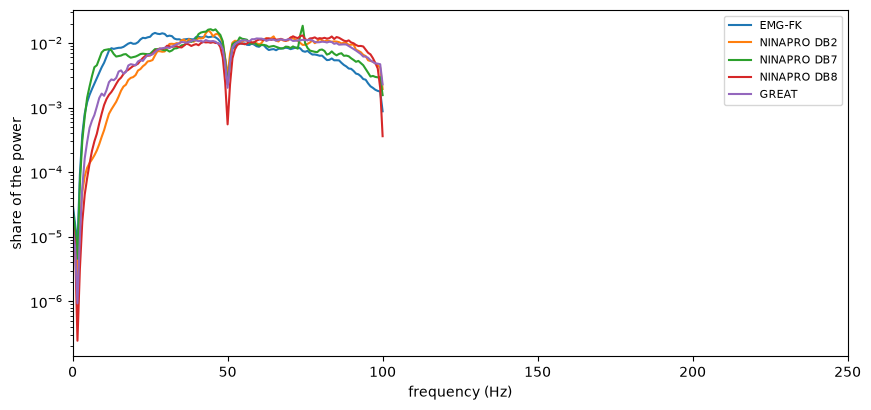

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, s in sessions.items():
    if s["covered"].any():
        f, share = spectrum([s])
        ax.semilogy(f, share, label=pretty(name))
ax.set(xlabel="frequency (Hz)", ylabel="share of the power", xlim=(0, 250))
ax.legend(fontsize=8)
plt.show()

They mostly do: all fall off below 20 Hz (the processor's high-pass) and dip at 50 Hz and its harmonics (the notch).
**EMG-FK is the exception**: above 100 Hz it carries about 10× less power than every public dataset, probably a
low-pass in its MindRove amplifier. A model trained on the other datasets would see its signals as unusually smooth;
worth checking on your own band too before testing on it.